# Assignment 8: Continual Learning and Test in Production

**Hiren Patel**

In [1]:
# I import everything I need
import time, copy, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader
import torchvision
from scipy import stats

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# I fix the seeds so the results are repeatable
torch.manual_seed(0); np.random.seed(0)

CLASSES = ["airplane", "automobile", "bird", "cat", "deer",
           "dog", "frog", "horse", "ship", "truck"]
SUBSAMPLE = None   # I keep None to use all data (set to a number only for a quick test)

Device: cuda


**Interpretation:** The output `Device: cuda` means PyTorch found my NVIDIA GPU (Graphics Processing Unit) and will train on it. This is why every training run below finishes in seconds instead of minutes.

## 1. Load CIFAR-10 and create Subset A and Subset B

I reuse the CIFAR-10 files I already downloaded in Assignment 6 (`../Assignment6/data`), so nothing needs to be downloaded again. I load the raw arrays once into tensors, which is much faster than reading images one by one.

In [2]:
DATA_DIR = "../Assignment6/data"
train_raw = torchvision.datasets.CIFAR10(DATA_DIR, train=True, download=True)
test_raw  = torchvision.datasets.CIFAR10(DATA_DIR, train=False, download=True)

# I use the same CIFAR-10 mean and std as in Assignment 6
MEAN = torch.tensor([0.4914, 0.4822, 0.4465]).view(1, 3, 1, 1)
STD  = torch.tensor([0.2470, 0.2435, 0.2616]).view(1, 3, 1, 1)

def to_tensors(ds):
    # I convert uint8 images (N, 32, 32, 3) to normalised float tensors (N, 3, 32, 32)
    x = torch.tensor(np.asarray(ds.data)).permute(0, 3, 1, 2).float() / 255.0
    x = (x - MEAN) / STD
    y = torch.tensor(np.asarray(ds.targets)).long()
    return x, y

X_train_all, y_train_all = to_tensors(train_raw)
X_test, y_test = to_tensors(test_raw)

if SUBSAMPLE:
    X_train_all, y_train_all = X_train_all[:SUBSAMPLE], y_train_all[:SUBSAMPLE]
    X_test, y_test = X_test[:SUBSAMPLE // 5], y_test[:SUBSAMPLE // 5]

# I hold out 10% of the training data as a validation set
g = torch.Generator().manual_seed(0)
perm = torch.randperm(len(X_train_all), generator=g)
n_val = len(perm) // 10
X_val, y_val = X_train_all[perm[:n_val]], y_train_all[perm[:n_val]]
X_train, y_train = X_train_all[perm[n_val:]], y_train_all[perm[n_val:]]

def subset(X, y, classes):
    mask = torch.isin(y, torch.tensor(classes))
    return X[mask], y[mask]

A_CLASSES, B_CLASSES = [0, 1, 2, 3, 4], [5, 6, 7, 8, 9]
XA_tr, yA_tr = subset(X_train, y_train, A_CLASSES)
XB_tr, yB_tr = subset(X_train, y_train, B_CLASSES)
XA_val, yA_val = subset(X_val, y_val, A_CLASSES)
XB_val, yB_val = subset(X_val, y_val, B_CLASSES)
XA_te, yA_te = subset(X_test, y_test, A_CLASSES)
XB_te, yB_te = subset(X_test, y_test, B_CLASSES)

print(f"Subset A train: {len(XA_tr)} | val: {len(XA_val)} | test: {len(XA_te)}")
print(f"Subset B train: {len(XB_tr)} | val: {len(XB_val)} | test: {len(XB_te)}")
print("Class counts A train:", torch.bincount(yA_tr, minlength=10)[:5].tolist())
print("Class counts B train:", torch.bincount(yB_tr, minlength=10)[5:].tolist())

C:\Users\patel\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\torchvision\datasets\cifar.py:83: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  entry = pickle.load(f, encoding="latin1")


Subset A train: 22462 | val: 2538 | test: 5000
Subset B train: 22538 | val: 2462 | test: 5000
Class counts A train: [4489, 4490, 4494, 4491, 4498]
Class counts B train: [4528, 4500, 4530, 4500, 4480]


**Interpretation:** The data loaded from my Assignment 6 folder without downloading again. The yellow message is only a deprecation warning from NumPy 2.4 inside torchvision's CIFAR loader. It does not affect the data. After holding out 10% for validation, Subset A (classes 0 to 4) has 22,462 training images, 2,538 validation images and 5,000 test images. Subset B (classes 5 to 9) has 22,538, 2,462 and 5,000. The class counts are all about 4,500 per class, so both subsets are balanced and no class can dominate training.

## 2. Model and helper functions

I use a small VGG-style CNN (Convolutional Neural Network) like the one in Assignment 6. It always has **10 outputs**, so the same network can later learn the new classes without changing its shape.

In [3]:
class SmallCNN(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        def block(cin, cout):
            return nn.Sequential(
                nn.Conv2d(cin, cout, 3, padding=1), nn.BatchNorm2d(cout), nn.ReLU(),
                nn.Conv2d(cout, cout, 3, padding=1), nn.BatchNorm2d(cout), nn.ReLU(),
                nn.MaxPool2d(2))
        self.features = nn.Sequential(block(3, 32), block(32, 64), block(64, 128))
        self.classifier = nn.Sequential(nn.Flatten(), nn.Dropout(0.3),
                                        nn.Linear(128 * 4 * 4, 256), nn.ReLU(),
                                        nn.Linear(256, num_classes))
    def forward(self, x):
        return self.classifier(self.features(x))

def augment(x):
    # I add random horizontal flips and small shifts so the model generalises better
    flip = torch.rand(x.size(0), device=x.device) < 0.5
    x = torch.where(flip.view(-1, 1, 1, 1), x.flip(3), x)
    pad = F.pad(x, (4, 4, 4, 4), mode="reflect")
    i, j = np.random.randint(0, 9, size=2)
    return pad[:, :, i:i + 32, j:j + 32]

@torch.no_grad()
def accuracy(model, X, y, bs=1000):
    model.eval()
    correct = 0
    for k in range(0, len(X), bs):
        xb, yb = X[k:k + bs].to(device), y[k:k + bs].to(device)
        correct += (model(xb).argmax(1) == yb).sum().item()
    return correct / len(X)

@torch.no_grad()
def predict(model, X, bs=1000):
    model.eval()
    return torch.cat([model(X[k:k + bs].to(device)).argmax(1).cpu() for k in range(0, len(X), bs)])

def train(model, X, y, epochs, lr, tag, history=None, bs=128):
    # I train the model and record accuracy on old (A) and new (B) validation data after every epoch
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    loader = DataLoader(TensorDataset(X, y), batch_size=bs, shuffle=True)
    start = time.time()
    for ep in range(1, epochs + 1):
        model.train()
        total, n = 0.0, 0
        for xb, yb in loader:
            xb, yb = augment(xb.to(device)), yb.to(device)
            opt.zero_grad()
            loss = F.cross_entropy(model(xb), yb)
            loss.backward(); opt.step()
            total += loss.item() * len(xb); n += len(xb)
        accA, accB = accuracy(model, XA_val, yA_val), accuracy(model, XB_val, yB_val)
        if history is not None:
            history.append({"method": tag, "epoch": ep, "loss": total / n, "val_A": accA, "val_B": accB})
        print(f"[{tag}] epoch {ep}/{epochs}  loss {total / n:.3f}  val_A {accA:.3f}  val_B {accB:.3f}")
    elapsed = time.time() - start
    return elapsed, epochs * len(X)   # I return training time and number of samples processed

**Interpretation:** The important design choice is that the network always has 10 outputs, even when it is only trained on 5 classes. This lets the same model learn the new classes later without changing its architecture. The `train` function also checks accuracy on old (A) and new (B) validation data after every epoch, which is how I can watch forgetting happen.

## 3. Train the initial model on Subset A only

In [4]:
EPOCHS_INITIAL = 8
history = []
initial_model = SmallCNN().to(device)
t_init, s_init = train(initial_model, XA_tr, yA_tr, EPOCHS_INITIAL, 1e-3, "initial (A only)", history)

init_A = accuracy(initial_model, XA_te, yA_te)
init_B = accuracy(initial_model, XB_te, yB_te)
print(f"\nInitial model test accuracy -> old classes A: {init_A:.3f} | new classes B: {init_B:.3f}")
torch.save(initial_model.state_dict(), "initial_model.pth")

[initial (A only)] epoch 1/8  loss 0.967  val_A 0.626  val_B 0.000
[initial (A only)] epoch 2/8  loss 0.714  val_A 0.753  val_B 0.000
[initial (A only)] epoch 3/8  loss 0.606  val_A 0.783  val_B 0.000
[initial (A only)] epoch 4/8  loss 0.535  val_A 0.827  val_B 0.000
[initial (A only)] epoch 5/8  loss 0.472  val_A 0.832  val_B 0.000
[initial (A only)] epoch 6/8  loss 0.431  val_A 0.863  val_B 0.000
[initial (A only)] epoch 7/8  loss 0.395  val_A 0.841  val_B 0.000
[initial (A only)] epoch 8/8  loss 0.375  val_A 0.857  val_B 0.000

Initial model test accuracy -> old classes A: 0.856 | new classes B: 0.000


**Interpretation:** The loss drops steadily from 0.967 to 0.375 over 8 epochs, and validation accuracy on the old classes rises from 0.626 to about 0.86. On the test set the initial model gets 0.856 on classes A, which is a good result for a small CNN (Convolutional Neural Network). Its accuracy on classes B is exactly 0.000 in every epoch. This is expected, because the model has never seen a dog, frog, horse, ship or truck, so it can only answer with one of the five classes it knows. In production this is what happens when new categories appear that were not in the training data.

## 4. Update the model with the new data (Subset B)

In [5]:
EPOCHS_STATELESS = 8
EPOCHS_STATEFUL = 4
results = {}

# 4a. Stateless: new model from scratch on A + B
X_AB, y_AB = torch.cat([XA_tr, XB_tr]), torch.cat([yA_tr, yB_tr])
stateless_model = SmallCNN().to(device)
t, s = train(stateless_model, X_AB, y_AB, EPOCHS_STATELESS, 1e-3, "stateless (A+B scratch)", history)
results["Stateless retrain"] = {"model": stateless_model, "time_s": t, "samples": s}

[stateless (A+B scratch)] epoch 1/8  loss 1.391  val_A 0.547  val_B 0.649
[stateless (A+B scratch)] epoch 2/8  loss 0.978  val_A 0.637  val_B 0.704
[stateless (A+B scratch)] epoch 3/8  loss 0.827  val_A 0.662  val_B 0.634
[stateless (A+B scratch)] epoch 4/8  loss 0.725  val_A 0.724  val_B 0.827
[stateless (A+B scratch)] epoch 5/8  loss 0.646  val_A 0.662  val_B 0.838
[stateless (A+B scratch)] epoch 6/8  loss 0.605  val_A 0.660  val_B 0.850
[stateless (A+B scratch)] epoch 7/8  loss 0.572  val_A 0.781  val_B 0.816
[stateless (A+B scratch)] epoch 8/8  loss 0.529  val_A 0.782  val_B 0.859


**Interpretation:** Stateless retraining starts from a fresh, random model and learns all 10 classes together. It begins weaker than the initial model (val_A 0.547 after epoch 1) because it starts from zero and the task is now harder: it must choose between 10 classes instead of 5. By epoch 8 it reaches 0.782 on old classes and 0.859 on new classes. The validation accuracy jumps around a little between epochs (for example val_A 0.724, then 0.662, then 0.781), which is normal for a short training run without a learning-rate schedule. More epochs would probably make it more stable and more accurate.

In [6]:
# 4b. Stateful naive: copy the initial model and continue on B only
naive_model = copy.deepcopy(initial_model)
t, s = train(naive_model, XB_tr, yB_tr, EPOCHS_STATEFUL, 3e-4, "stateful naive (B only)", history)
results["Stateful naive"] = {"model": naive_model, "time_s": t, "samples": s}

[stateful naive (B only)] epoch 1/4  loss 2.347  val_A 0.000  val_B 0.730
[stateful naive (B only)] epoch 2/4  loss 0.617  val_A 0.000  val_B 0.862
[stateful naive (B only)] epoch 3/4  loss 0.376  val_A 0.000  val_B 0.892
[stateful naive (B only)] epoch 4/4  loss 0.314  val_A 0.000  val_B 0.911


**Interpretation:** This is catastrophic forgetting in action. After just one epoch on the new data, accuracy on the old classes drops from 0.857 to 0.000 and stays at zero. At the same time, accuracy on the new classes climbs quickly to 0.911, because the model already has useful feature detectors (edges, shapes, colours) from training on A. The model has completely overwritten its old knowledge: because it only sees B images, it learns that the answer is always one of classes 5 to 9.

In [7]:
# 4c. Stateful with replay: continue on B + 20% of A (the replay buffer)
REPLAY_FRACTION = 0.2
idx = torch.randperm(len(XA_tr), generator=g)[: int(REPLAY_FRACTION * len(XA_tr))]
X_replay = torch.cat([XB_tr, XA_tr[idx]])
y_replay = torch.cat([yB_tr, yA_tr[idx]])
print("Replay buffer size from A:", len(idx), "| total training rows:", len(X_replay))

replay_model = copy.deepcopy(initial_model)
t, s = train(replay_model, X_replay, y_replay, EPOCHS_STATEFUL, 3e-4, "stateful replay (B + 20% A)", history)
results["Stateful + replay"] = {"model": replay_model, "time_s": t, "samples": s}

Replay buffer size from A: 4492 | total training rows: 27030
[stateful replay (B + 20% A)] epoch 1/4  loss 2.034  val_A 0.240  val_B 0.828
[stateful replay (B + 20% A)] epoch 2/4  loss 0.749  val_A 0.455  val_B 0.881
[stateful replay (B + 20% A)] epoch 3/4  loss 0.615  val_A 0.532  val_B 0.889
[stateful replay (B + 20% A)] epoch 4/4  loss 0.557  val_A 0.512  val_B 0.902


**Interpretation:** The replay buffer adds 4,492 old images (20% of Subset A), so the model trains on 27,030 rows instead of 22,538. In epoch 1, accuracy on the old classes still drops sharply, from 0.857 to 0.240, but it does not hit zero. Then it recovers to about 0.51 to 0.53 as the model sees the old examples again. Accuracy on the new classes reaches 0.902, almost as high as the naive model. Replay keeps a good part of the old knowledge for only a small extra cost, but 20% replay and 4 epochs are not enough to fully protect classes A.

## 5. Compare the methods

In [8]:
rows = [{"method": "Initial (A only)", "acc_A_old": init_A, "acc_B_new": init_B,
         "acc_all": accuracy(initial_model, X_test, y_test), "train_time_s": 0.0, "samples_processed": 0}]
for name, r in results.items():
    m = r["model"]
    rows.append({"method": name,
                 "acc_A_old": accuracy(m, XA_te, yA_te),
                 "acc_B_new": accuracy(m, XB_te, yB_te),
                 "acc_all": accuracy(m, X_test, y_test),
                 "train_time_s": r["time_s"],
                 "samples_processed": r["samples"]})
comparison = pd.DataFrame(rows).set_index("method")
# I measure forgetting as the drop in old-class accuracy compared with the initial model
comparison["forgetting_A"] = init_A - comparison["acc_A_old"]
comparison.round(3)

,acc_A_old,acc_B_new,acc_all,train_time_s,samples_processed,forgetting_A
method,,,,,,
Initial (A only),0.856,0.000,0.428,0.000,0,0.000
Stateless retrain,0.771,0.855,0.813,28.920,360000,0.086
Stateful naive,0.000,0.910,0.455,7.654,90152,0.856
Stateful + replay,0.510,0.890,0.700,8.982,108120,0.347


**Interpretation:** This table is the main result. The initial model scores 0.856 on old classes but 0.000 on new classes, so only 0.428 overall. The **stateless retrained** model is the best all-rounder at 0.813 overall (0.771 old, 0.855 new). Its "forgetting" of 0.086 is not real forgetting. It comes from the harder 10-class task, where similar classes get confused (for example cat and dog, or automobile and truck). The **stateful naive** model is the best on new classes (0.910) but forgets all old classes (forgetting 0.856), so it is only 0.455 overall, barely better than the initial model. **Stateful + replay** sits in the middle at 0.700 overall: it keeps 0.510 on old classes and gets 0.890 on new classes. The cost columns show the trade-off. Stateless processed 360,000 samples in 28.9 seconds, while replay processed only 108,120 samples in 9.0 seconds, which is about 3.2 times cheaper. On a dataset this small that difference is seconds, but for a company retraining on millions of rows every day it means hours of GPU time and real money.

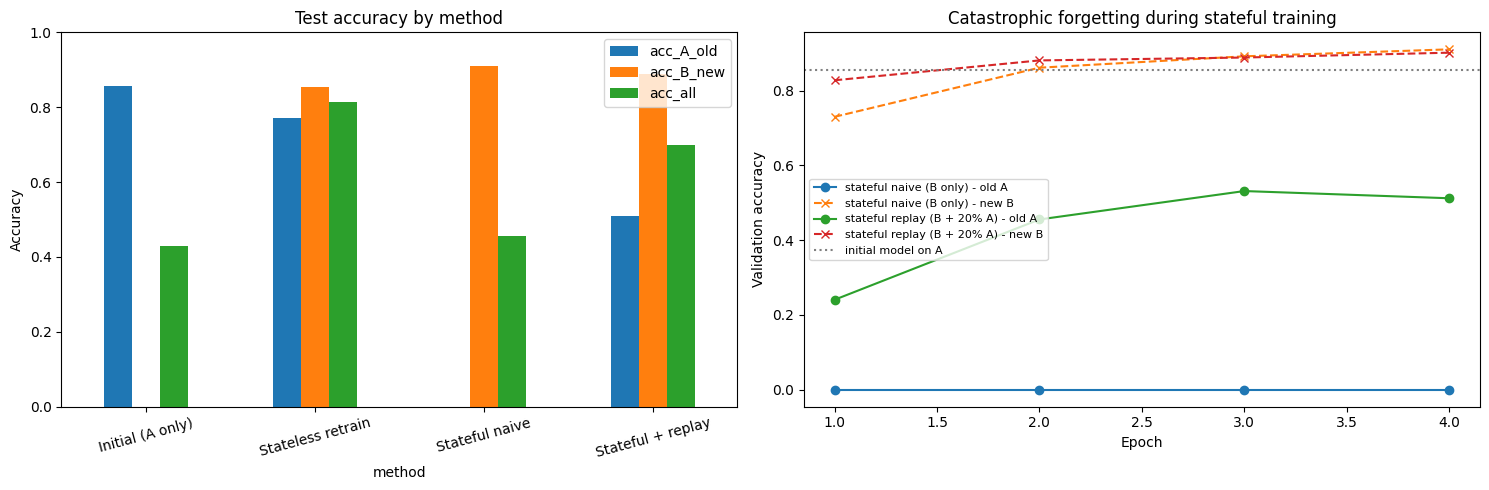

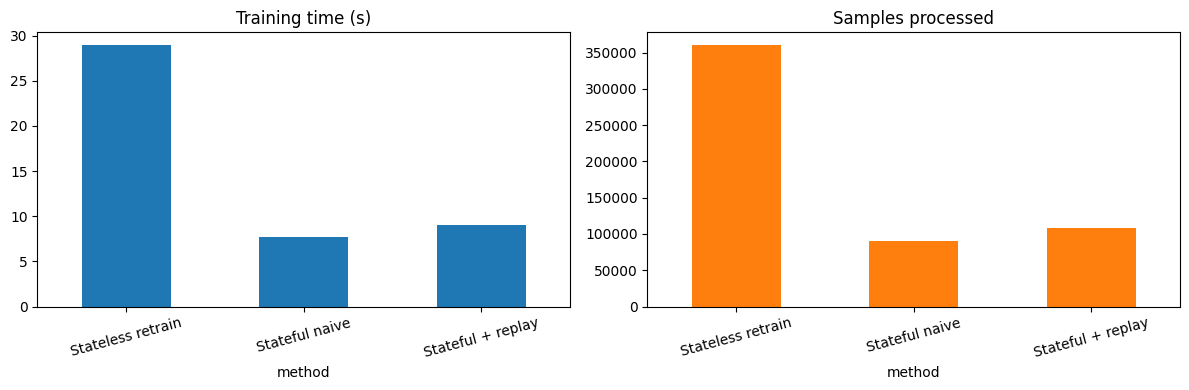

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

comparison[["acc_A_old", "acc_B_new", "acc_all"]].plot(kind="bar", ax=axes[0], rot=15)
axes[0].set_title("Test accuracy by method"); axes[0].set_ylabel("Accuracy"); axes[0].set_ylim(0, 1)

h = pd.DataFrame(history)
for tag in ["stateful naive (B only)", "stateful replay (B + 20% A)"]:
    d = h[h.method == tag]
    axes[1].plot(d.epoch, d.val_A, marker="o", label=f"{tag} - old A")
    axes[1].plot(d.epoch, d.val_B, marker="x", linestyle="--", label=f"{tag} - new B")
axes[1].axhline(init_A, color="grey", linestyle=":", label="initial model on A")
axes[1].set_title("Catastrophic forgetting during stateful training")
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Validation accuracy"); axes[1].legend(fontsize=8)
plt.tight_layout()
plt.savefig("method_comparison.png", dpi=100)
plt.show()

comparison[["train_time_s", "samples_processed"]].iloc[1:].plot(kind="bar", subplots=True, layout=(1, 2),
                                                                 figsize=(12, 4), rot=15, legend=False,
                                                                 title=["Training time (s)", "Samples processed"])
plt.tight_layout()
plt.savefig("training_cost.png", dpi=100)
plt.show()

**Interpretation:** In the left bar chart, the initial model has a tall blue bar (old classes) and no orange bar (new classes). The naive model is the opposite: a tall orange bar and no blue bar. Only stateless retraining has all three bars high and close together. In the right line chart, the blue line (naive, old classes) sits flat at zero from the first epoch, while the green line (replay, old classes) climbs back to about 0.5. Both dashed lines for the new classes rise above the grey dotted line, which marks the initial model's accuracy on A. The second figure shows the training cost: the stateless bar is about three times taller than the stateful bars, both in seconds and in samples processed.

## 6. A/B test in production

I simulate production traffic using the 10-class test set as "users". Each image is randomly assigned to group A (control = **stateless retrained** model) or group B (treatment = **stateful + replay** model). Each group only sees its own model's predictions. I then use a **two-proportion z-test** to check whether the difference in accuracy is statistically significant or could be due to chance.

In [10]:
def two_proportion_ztest(success_a, n_a, success_b, n_b):
    p_a, p_b = success_a / n_a, success_b / n_b
    p_pool = (success_a + success_b) / (n_a + n_b)
    se = math.sqrt(p_pool * (1 - p_pool) * (1 / n_a + 1 / n_b))
    z = (p_b - p_a) / se
    p_value = 2 * (1 - stats.norm.cdf(abs(z)))
    return p_a, p_b, z, p_value

# I pre-compute which test images each model gets right
correct = {name: (predict(r["model"], X_test) == y_test).numpy() for name, r in results.items()}

rng = np.random.default_rng(0)
group = rng.random(len(y_test)) < 0.5     # True = group B (treatment)
ctrl, treat = "Stateless retrain", "Stateful + replay"
sa, na = correct[ctrl][~group].sum(), (~group).sum()
sb, nb = correct[treat][group].sum(), group.sum()
p_a, p_b, z, p_value = two_proportion_ztest(sa, na, sb, nb)

print(f"Group A ({ctrl}):  {sa}/{na} correct = {p_a:.3f}")
print(f"Group B ({treat}): {sb}/{nb} correct = {p_b:.3f}")
print(f"Difference (B - A): {p_b - p_a:+.3f}")
print(f"z = {z:.3f}, p-value = {p_value:.4f}")
print("Result:", "significant at 0.05" if p_value < 0.05 else "NOT significant at 0.05 (no clear winner)")

Group A (Stateless retrain):  4048/5010 correct = 0.808
Group B (Stateful + replay): 3535/4990 correct = 0.708
Difference (B - A): -0.100
z = -11.629, p-value = 0.0000
Result: significant at 0.05


**Interpretation:** I split the 10,000 test images randomly into two groups of about 5,000 "users". The control group, served by the stateless model, got 80.8% correct, and the treatment group, served by stateful + replay, got 70.8% correct. That is a difference of 10 percentage points. The z-score of -11.6 means the difference is more than 11 standard errors away from zero, and the p-value is effectively 0. So the difference is statistically significant, not luck. The A/B test gives a clear decision: keep the stateless retrained model in production and don't roll out the replay model.

In [11]:
# I also run the same A/B test for the naive model vs the stateless model, to show a clear case
sn = correct["Stateful naive"][group].sum()
p_a2, p_b2, z2, p2 = two_proportion_ztest(sa, na, sn, nb)
print(f"Stateless {p_a2:.3f} vs Stateful naive {p_b2:.3f}: z = {z2:.2f}, p-value = {p2:.2e}")

Stateless 0.808 vs Stateful naive 0.457: z = -36.43, p-value = 0.00e+00


**Interpretation:** As a sanity check, the naive model loses by a huge margin (0.808 vs 0.457, z = -36.4). An A/B test would catch this immediately and stop the rollout. This shows why companies never replace a production model just because it looks good on the newest data. The naive model looked great on B (0.910) but would have hurt users looking for the old classes.

## 7. Multi-armed bandit (ε-greedy)

An A/B test keeps sending 50% of users to the worse model until the test ends. A **bandit** learns while it serves: most of the time (1 − ε) it sends a request to the model with the best accuracy so far (exploit), and sometimes (ε = 10%) it tries a random model (explore). The reward is 1 if the prediction is correct and 0 if it is wrong. I stream the test images one by one, in random order, as incoming requests.

In [12]:
arms = list(results.keys())          # the three candidate models
reward_table = np.stack([correct[a] for a in arms], axis=1).astype(float)   # shape (n_requests, n_arms)

def run_bandit(epsilon, seed=0):
    r = np.random.default_rng(seed)
    order = r.permutation(len(reward_table))
    counts, values = np.zeros(len(arms)), np.zeros(len(arms))
    chosen, rewards = [], []
    for t, i in enumerate(order):
        if t < len(arms):                      # I try every arm once first
            a = t
        elif r.random() < epsilon:
            a = r.integers(len(arms))          # explore
        else:
            a = int(np.argmax(values))         # exploit
        rew = reward_table[i, a]
        counts[a] += 1
        values[a] += (rew - values[a]) / counts[a]   # I update the running average reward
        chosen.append(a); rewards.append(rew)
    return np.array(chosen), np.array(rewards), counts, values

chosen, rewards, counts, values = run_bandit(epsilon=0.1)

# I compare with two baselines: random routing and always using the best model (oracle)
r = np.random.default_rng(0)
order = r.permutation(len(reward_table))
random_rewards = reward_table[order, r.integers(len(arms), size=len(order))]
best_arm = int(reward_table.mean(0).argmax())
oracle_rewards = reward_table[order, best_arm]

print("Traffic share per model:")
for a, c, v in zip(arms, counts, values):
    print(f"  {a:20s} {c / counts.sum():6.1%} of requests, estimated accuracy {v:.3f}")
print(f"\nOverall accuracy  bandit: {rewards.mean():.3f} | random routing: {random_rewards.mean():.3f} | "
      f"always best ({arms[best_arm]}): {oracle_rewards.mean():.3f}")

Traffic share per model:
  Stateless retrain     93.1% of requests, estimated accuracy 0.811
  Stateful naive         3.6% of requests, estimated accuracy 0.490
  Stateful + replay      3.3% of requests, estimated accuracy 0.763

Overall accuracy  bandit: 0.798 | random routing: 0.656 | always best (Stateless retrain): 0.813


**Interpretation:** The ε-greedy bandit (ε = 0.1) quickly found that the stateless model is best and sent it 93.1% of requests. The other two models received only about 3.5% each, which is the 10% exploration split across all arms. The bandit's overall accuracy was 0.798, very close to the 0.813 I would get by always using the best model, and much better than random routing (0.656). Its estimates for the weaker models are rough (0.490 for naive vs a true 0.455, and 0.763 for replay vs a true 0.700) because they were tried only a few hundred times each. The bandit didn't need accurate estimates for weak models, only enough evidence to stop using them.

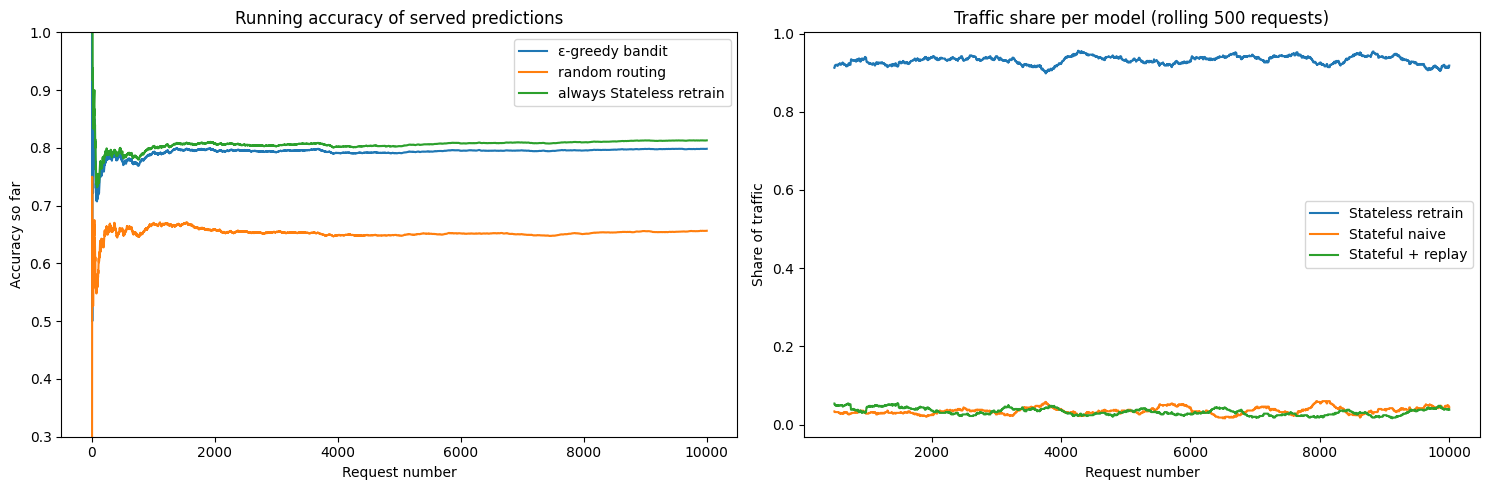

In [13]:
steps = np.arange(1, len(rewards) + 1)
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].plot(steps, np.cumsum(rewards) / steps, label="ε-greedy bandit")
axes[0].plot(steps, np.cumsum(random_rewards) / steps, label="random routing")
axes[0].plot(steps, np.cumsum(oracle_rewards) / steps, label=f"always {arms[best_arm]}")
axes[0].set_title("Running accuracy of served predictions"); axes[0].set_xlabel("Request number")
axes[0].set_ylabel("Accuracy so far"); axes[0].legend(); axes[0].set_ylim(0.3, 1)

window = 500
for k, a in enumerate(arms):
    share = pd.Series((chosen == k).astype(float)).rolling(window).mean()
    axes[1].plot(steps, share, label=a)
axes[1].set_title(f"Traffic share per model (rolling {window} requests)")
axes[1].set_xlabel("Request number"); axes[1].set_ylabel("Share of traffic"); axes[1].legend()
plt.tight_layout()
plt.savefig("bandit.png", dpi=100)
plt.show()

**Interpretation:** In the left chart, the bandit's line (blue) jumps around for the first few hundred requests while it is still exploring. It then settles at about 0.80, just under the green "always best" line, and far above the orange random-routing line at about 0.65. In the right chart, the stateless model's share of traffic stays at about 92 to 95% for the whole stream, while the other two models stay at about 3 to 5%. This shows the main advantage of a bandit over an A/B test: it moves traffic to the winner while the test is still running, so fewer users get the worse model. The small gap between the bandit and the green line is the "cost of exploration".

In [14]:
# I print a compact summary of all key numbers for my write-up
print("=== RESULTS SUMMARY ===")
print(comparison.round(3).to_string())
print(f"\nA/B: stateless {p_a:.3f} vs replay {p_b:.3f}, z={z:.3f}, p={p_value:.4f}")
print(f"A/B: stateless {p_a2:.3f} vs naive {p_b2:.3f}, z={z2:.2f}, p={p2:.2e}")
print("Bandit share:", {a: round(float(c / counts.sum()), 3) for a, c in zip(arms, counts)})
print(f"Bandit acc {rewards.mean():.3f} | random {random_rewards.mean():.3f} | best {oracle_rewards.mean():.3f}")

=== RESULTS SUMMARY ===
                   acc_A_old  acc_B_new  acc_all  train_time_s  samples_processed  forgetting_A
method                                                                                         
Initial (A only)       0.856      0.000    0.428         0.000                  0         0.000
Stateless retrain      0.771      0.855    0.813        28.920             360000         0.086
Stateful naive         0.000      0.910    0.455         7.654              90152         0.856
Stateful + replay      0.510      0.890    0.700         8.982             108120         0.347

A/B: stateless 0.808 vs replay 0.708, z=-11.629, p=0.0000
A/B: stateless 0.808 vs naive 0.457, z=-36.43, p=0.00e+00
Bandit share: {'Stateless retrain': 0.931, 'Stateful naive': 0.036, 'Stateful + replay': 0.033}
Bandit acc 0.798 | random 0.656 | best 0.813


**Interpretation:** This cell collects all the key numbers in one place for my write-up. The overall story is that stateless retraining wins on accuracy (0.813) but costs the most, naive stateful training is cheap but forgets everything old, and replay is a cheap middle ground (0.700). Both the A/B test and the bandit independently chose the stateless model.

## 8. Overall conclusion and recommendations

**What I learned about updating models.** The initial model scored 0.856 on the classes it knew and 0.000 on the new ones, so a model that is never updated becomes useless when new categories appear. Stateless retraining (from scratch on A + B) gave the best overall accuracy of 0.813, but it processed about 3.3 times more samples than stateful training (360,000 vs about 100,000). Naive stateful training learned the new classes best (0.910) but showed catastrophic forgetting: accuracy on the old classes fell from 0.856 to exactly 0 after a single epoch. Adding a replay buffer of 20% old data reduced forgetting a lot (old-class accuracy back to 0.510) at almost the same cost as naive training (9.0 s vs 7.7 s), but in my run it was still clearly below stateless retraining.

**What I learned about testing in production.** The A/B test showed that stateless retraining beats stateful + replay by 10 percentage points (0.808 vs 0.708, p ≈ 0), so the decision is clear and backed by statistics. The ε-greedy bandit reached the same conclusion on its own, and sent 93% of traffic to the stateless model. It achieved 0.798 accuracy, close to the best possible 0.813 and far above random routing at 0.656. The bandit "wastes" fewer users on weaker models than a 50/50 A/B test, but it gives less precise estimates for the models it rarely uses.

**Recommendations**
1. For a small model and dataset like this one, use **stateless retraining** on a schedule (for example weekly), because the compute cost is low and the accuracy is the best.
2. For large models or very frequent updates, use **stateful training with replay** and make the replay buffer bigger (for example 30 to 50%) or train for more epochs. Never use naive fine-tuning on new data only, because it destroys old knowledge.
3. Always test a new model before full rollout. Use an **A/B test** when I need a clear, statistically reliable answer. Use a **bandit** when I want to protect users from a bad model while still learning, or when there are many candidate models.
4. Monitor accuracy per class group (old vs new) in production, not just overall accuracy. The naive model looked excellent on new data (0.910) while silently failing on every old class.
5. Combine both approaches: run cheap stateful updates often, and run a full stateless retrain from time to time to reset any slow drift or forgetting.
